# Term paper TECH 2

Candidate numbers: XXX, XXX, XXX

## Task 1: Import and prepare the data

### Approach

Because of the size of the files, we read them through functions and keep only the data we need. This means that the code won't read through the entire file when we use it.

In [118]:
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# Paths to the different files
IPC_FILE = "data/202608_EPO_IPC.txt"
CPC_FILE = "data/202608_CPC_Classes.txt"
APP_FILE = "data/202608_EPO_App_reg.txt"

# Sample period
sample_start = 2000
sample_end = 2019

# Grouping the patents by Y02E code
main_groups = {
    "10": "Renewable energy",
    "20": "Efficient combustion",
    "30": "Nuclear energy",
    "40": "Efficient power transmission",
    "50": "Non-fossil fuels",
    "60": "Storage and hydrogen",
    "70": "Other energy conversion",
}

# Table 2: first digit after the slash in main group 10 -> technology.
# Digits not listed here (e.g. 0 in 'Y02E 10/00') belong to no technology.
technologies = {
    "1": "Other renewables",
    "2": "Other renewables",
    "3": "Other renewables",
    "4": "Solar",
    "5": "Solar",
    "6": "Solar",
    "7": "Wind",
}

# All category labels, in a fixed order
main_group_labels = list(main_groups.values())
technology_labels = ["Solar", "Wind", "Other renewables"]
all_labels = main_group_labels + technology_labels

# Fixed colours, so a group or technology has the same colour in every figure
main_group_colors = {
    "Renewable energy": "royalblue",
    "Efficient combustion": "orangered",
    "Nuclear energy": "mediumseagreen",
    "Efficient power transmission": "orange",
    "Non-fossil fuels": "hotpink",
    "Storage and hydrogen": "green",
    "Other energy conversion": "slateblue",
}
tech_colors = {
    "Solar": "orange",
    "Wind": "royalblue",
    "Other renewables": "mediumseagreen",
}

In [ ]:
def read_sample(path, first_year, last_year):
    """Read the sample: one row per EPO application with priority year in a period.

    The IPC file has one row per IPC code, so an application appears on several
    rows. We keep only ``appln_id`` and ``prio_year`` (the priority year is the
    same on all rows of an application), keep the years in the period and drop
    the repeated rows.

    Parameters
    ----------
    path : str
        Path to the IPC file.
    first_year, last_year : int
        First and last priority year of the sample (inclusive).

    Returns
    -------
    pandas.DataFrame
        Columns ``appln_id`` and ``prio_year``, one row per application.
    """


    ipc = pd.read_csv(path, sep='|')
    ipc = ipc[['appln_id', 'prio_year']]
    in_period = (ipc['prio_year'] >= first_year) & (ipc['prio_year'] <= last_year)
    return ipc.loc[in_period].drop_duplicates('appln_id').reset_index(drop=True)

In [121]:
def read_y02e_codes(path, sample_ids):
    """Read the Y02E codes of the applications in the sample.

    The CPC file has one row per CPC code. Only about 0.6% of the 35.6M rows
    are Y02E codes, so we keep the rows whose code starts with ``'Y02E'`` and
    whose application is in the sample.

    Parameters
    ----------
    path : str
        Path to the CPC file.
    sample_ids : pandas.Series
        ``appln_id`` of the applications in the sample.

    Returns
    -------
    pandas.DataFrame
        Columns ``appln_id`` and ``CPC_Class``, one row per Y02E code of a
        patent in the sample.
    """
    cpc = pd.read_csv(path, sep='|')
    is_y02e = cpc['CPC_Class'].str.startswith('Y02E')
    in_sample = cpc['appln_id'].isin(sample_ids)
    return cpc.loc[is_y02e & in_sample].reset_index(drop=True)

In [122]:
def read_applicants(path, sample_ids):
    """Read the applicants of the applications in the sample.

    An applicant whose address is linked to several regions appears on several
    rows that are identical apart from the region columns. After selecting the
    four columns we need, these rows are exact duplicates of each other and
    are dropped, so every applicant counts once per patent. Names are then
    converted to upper case, so that names that differ only in capitalisation
    are the same applicant.

    Parameters
    ----------
    path : str
        Path to the applicant file.
    sample_ids : pandas.Series
        ``appln_id`` of the applications in the sample.

    Returns
    -------
    pandas.DataFrame
        Columns ``appln_id``, ``app_name`` (upper case), ``ctry_code`` and
        ``app_share``.
    """
    # Without these two options the country code 'NA' (Namibia) is read as missing
    app = pd.read_csv(path, sep='|', keep_default_na=False, na_values=[''])
    app = app[['appln_id', 'app_name', 'ctry_code', 'app_share']]
    app = app.loc[app['appln_id'].isin(sample_ids)].drop_duplicates().reset_index(drop=True)
    app['app_name'] = app['app_name'].str.upper()
    return app

In [ ]:
def classify_codes(codes):
    """Add the main group (Table 1) and technology (Table 2) of each Y02E code.

    Codes look like ``'Y02E  10/549'`` (the number of spaces varies). Each
    code is split at the slash with ``str.partition``; the two digits before
    the slash (main group) are found by partitioning at ``'Y02E'`` and
    stripping the spaces, and the first digit after the slash (technology
    digit) is taken with ``str.get(0)``. Dictionaries map them to labels.

    Parameters
    ----------
    codes : pandas.DataFrame
        Must contain a ``CPC_Class`` column with Y02E codes.

    Returns
    -------
    pandas.DataFrame
        ``codes`` with two new columns, ``main_group`` and ``technology``. The
        technology is missing for codes outside main group 10 and for codes in
        main group 10 not listed in Table 2.
    """
    # Split each code at the slash: 'Y02E  10/549' -> 'Y02E  10', '/', '549'
    parts = codes['CPC_Class'].str.partition('/')
    # Main group: the digits after 'Y02E', 'Y02E  10' -> '10'
    main_digits = parts[0].str.partition('Y02E')[2].str.strip()
    # Technology digit: first character after the slash, '549' -> '5'
    tech_digit = parts[2].str.get(0)
    main_group = main_digits.map(main_groups)
    technology = tech_digit.map(technologies).where(main_digits == '10')
    codes = codes.copy()
    codes['main_group'] = main_group
    codes['technology'] = technology
    return codes

In [124]:
def build_green_categories(codes, sample):
    """Build a long table with one row per (green patent, category).

    The main group and the technology of each code are stacked into a single
    ``category`` column. Dropping duplicate (patent, category) pairs applies the
    counting rule: a patent counts once in each category, however many of its
    codes fall in it.

    Parameters
    ----------
    codes : pandas.DataFrame
        Output of :func:`classify_codes`.
    sample : pandas.DataFrame
        The sample, with ``appln_id`` and ``prio_year``.

    Returns
    -------
    pandas.DataFrame
        Columns ``appln_id``, ``category`` (a label from Table 1 or 2) and
        ``prio_year``.
    """
    main = codes[['appln_id', 'main_group']].rename(columns={'main_group': 'category'})
    tech = codes[['appln_id', 'technology']].rename(columns={'technology': 'category'})
    tech = tech.dropna()  # codes without a technology
    long = pd.concat([main, tech]).drop_duplicates()
    return long.merge(sample[['appln_id', 'prio_year']], on='appln_id', how='left')

### Read the data

Each file is read exactly once. The sample's `appln_id`s are passed on to the two other readers, so that they only
return rows for patents in the sample.

In [125]:
# 1) The sample: one row per EPO application with priority year 2000-2019
sample = read_sample(IPC_FILE, sample_start, sample_end)

# 2) All Y02E codes of patents in the sample, parsed once into main group and technology
green_codes = read_y02e_codes(CPC_FILE, sample['appln_id'])
green_codes = classify_codes(green_codes)

# 3) A patent is green if it has at least one Y02E code
sample['green'] = sample['appln_id'].isin(green_codes['appln_id'])

# 4) One row per (green patent, category) with the priority year (Tasks 3-5)
green_cat = build_green_categories(green_codes, sample)

# 5) The applicants of all patents in the sample (de-duplicated, upper-case names)
applicants = read_applicants(APP_FILE, sample['appln_id'])

green_cat.head()

,appln_id,category,prio_year
0,91,Nuclear energy,2004
1,103,Efficient combustion,2005
2,146,Renewable energy,2006
3,204,Efficient combustion,2008
4,240,Renewable energy,2007


### Checkpoints

The three checkpoints from the task are compared with our numbers. The `Match` column shows whether each of them
matches.

In [126]:
checkpoints = pd.DataFrame(
    {
        'Our result': [
            len(sample),
            sample['green'].sum(),
            round(applicants['app_share'].sum()),
        ],
        'Expected': [2_835_599, 114_924, 2_835_140],
    },
    index=[
        'EPO patent applications in the sample',
        'Green energy patents in the sample',
        'Sum of app_share (rounded)',
    ],
)
checkpoints['Match'] = checkpoints['Our result'] == checkpoints['Expected']
checkpoints

,Our result,Expected,Match
EPO patent applications in the sample,2835599,2835599,True
Green energy patents in the sample,114924,114924,True
Sum of app_share (rounded),2835140,2835140,True


### Overview of the data structure

* **Y02E codes per green patent.** We count *distinct* codes per patent, since a code listed twice for the same patent
  does not add information. In practice the choice does not matter: the data contain no duplicate (patent, code)
  rows, which the cell below checks.
* **Green patents in more than one main group.** `green_cat` already has one row per patent and main group, so we
  count how often each patent appears among the main-group rows.
* **Patents with applicants in more than one country.** The number of distinct `ctry_code`s per patent (`NA` is read as
  Namibia, not as a missing value).

In [ ]:
n_green = sample['green'].sum()

# Average number of distinct Y02E codes per green patent
n_distinct_codes = len(green_codes.drop_duplicates(['appln_id', 'CPC_Class']))
n_duplicate_codes = len(green_codes) - n_distinct_codes
avg_codes = n_distinct_codes / n_green

# Green patents that belong to more than one main group
is_main_group = green_cat['category'].isin(main_group_labels)
n_multi_group = (green_cat.loc[is_main_group, 'appln_id'].value_counts() > 1).sum()

# Patents in the sample with applicants in more than one country
countries = applicants[['appln_id', 'ctry_code']].drop_duplicates()
n_multi_country = (countries['appln_id'].value_counts() > 1).sum()

print(f'Duplicate (patent, Y02E code) rows: {n_duplicate_codes:,}')
print(f'Average number of Y02E codes per green patent: {avg_codes:.2f}')
print(f'Green patents in more than one main group: {n_multi_group:,}')
print(f'Patents with applicants in more than one country: {n_multi_country:,}')

Duplicate (patent, Y02E code) rows: 0
Average number of Y02E codes per green patent: 1.23
Green patents in more than one main group: 4,359
Patents with applicants in more than one country: 58,955


### Free memory

The checkpoints are the only place where we need the applicants of *all* patents in the sample. Task 5 only looks at
green patents, so we keep only their applicants (about 4% of the rows).
The code-level table `green_codes` is not needed after Task 1, because `green_cat` holds everything the later tasks
use.

In [128]:
applicants = applicants.loc[applicants['appln_id'].isin(green_cat['appln_id'])]
del green_codes, is_main_group

# Number of rows in the DataFrames that Tasks 2-5 work with
pd.Series(
    {
        'sample': len(sample),
        'green_cat': len(green_cat),
        'applicants': len(applicants),
    },
    name='Rows',
).to_frame()

,Rows
sample,2835599
green_cat,162166
applicants,126097


### Results of Task 1

**All three checkpoints match:** 2,835,599 patents in the sample, 114,924 green energy patents and an `app_share` sum
of 2,835,140.

**De-duplicating the applicants.** The region duplicates are removed by dropping rows that are identical in the four
columns we read (`appln_id`, `app_name`, `ctry_code`, `app_share`). This is exactly the rule in the task (rows that are
identical apart from the region columns), and it reproduces the checkpoint. Using `person_id` as the key instead would
not, because some region duplicates of the same applicant carry different `person_id`s.

**Overview of the data:**

* A green patent has on average **1.23** distinct Y02E codes. Most green patents have a single Y02E code, so counting
  codes instead of patents would only inflate the numbers somewhat, but the counting rule still matters.
* **4,359** green patents (3.8%) belong to more than one main group. The main-group counts in Task 3 therefore add up
  to slightly more than the number of green patents.
* **58,955** patents in the sample (2.1%) have applicants in more than one country. These patents would be counted
  several times if we counted whole patents per country, which is why Task 5 uses fractional counting.

After the checkpoints, only the applicants of green patents are kept, so the data that Tasks 2–5 work with are
small.

## Task 2 — Has green energy patenting slumped?

A single `groupby` on the priority year counts both the green patents (the sum of the boolean `green` column) and all
patents (the group size) in one pass.

In [129]:
yearly = sample.groupby('prio_year').agg(
    green=('green', 'sum'),
    total=('appln_id', 'size'),
)
yearly['green_share'] = yearly['green'] / yearly['total'] * 100
yearly.columns = ['Green energy patents', 'All patents', 'Green share (%)']
yearly.index.name = 'Priority year'
yearly.round(2)

,Green energy patents,All patents,Green share (%)
Priority year,,,
2000,2295,116789,1.97
2001,2506,115161,2.18
2002,2507,118892,2.11
2003,2863,124660,2.30
2004,3132,132552,2.36
2005,3656,137653,2.66
2006,4261,137191,3.11
2007,5082,135529,3.75
2008,5859,130726,4.48


To describe the slump with numbers instead of reading them off the figure, we let the data date it. The slump starts
in the last year before green patenting falls for the first time (the boom's peak), and ends in the last year
before it starts to grow again (the trough). We then compare these years with all patents.

In [130]:
green_change = yearly['Green energy patents'].diff()

# Peak of the boom: the year before the first fall in green patenting
slump_start = (green_change < 0).idxmax() - 1
# Trough: the year before the first rise after the peak
slump_end = (green_change.loc[slump_start + 1 :] > 0).idxmax() - 1

# Level and change (in %) of each column between key years
key_years = [sample_start, slump_start, slump_end, sample_end]
key = yearly.loc[key_years].T
key.columns = [
    f'{sample_start}',
    f'Peak ({slump_start})',
    f'Trough ({slump_end})',
    f'{sample_end}',
]
key['Change peak→trough (%)'] = (key.iloc[:, 2] / key.iloc[:, 1] - 1) * 100
key['Change trough→2019 (%)'] = (key.iloc[:, 3] / key.iloc[:, 2] - 1) * 100
key.round(1)

,2000,Peak (2011),Trough (2015),2019,Change peak→trough (%),Change trough→2019 (%)
Green energy patents,2295.0,8251.0,6508.0,8660.0,-21.1,33.1
All patents,116789.0,143392.0,154489.0,173460.0,7.7,12.3
Green share (%),2.0,5.8,4.2,5.0,-26.8,18.5


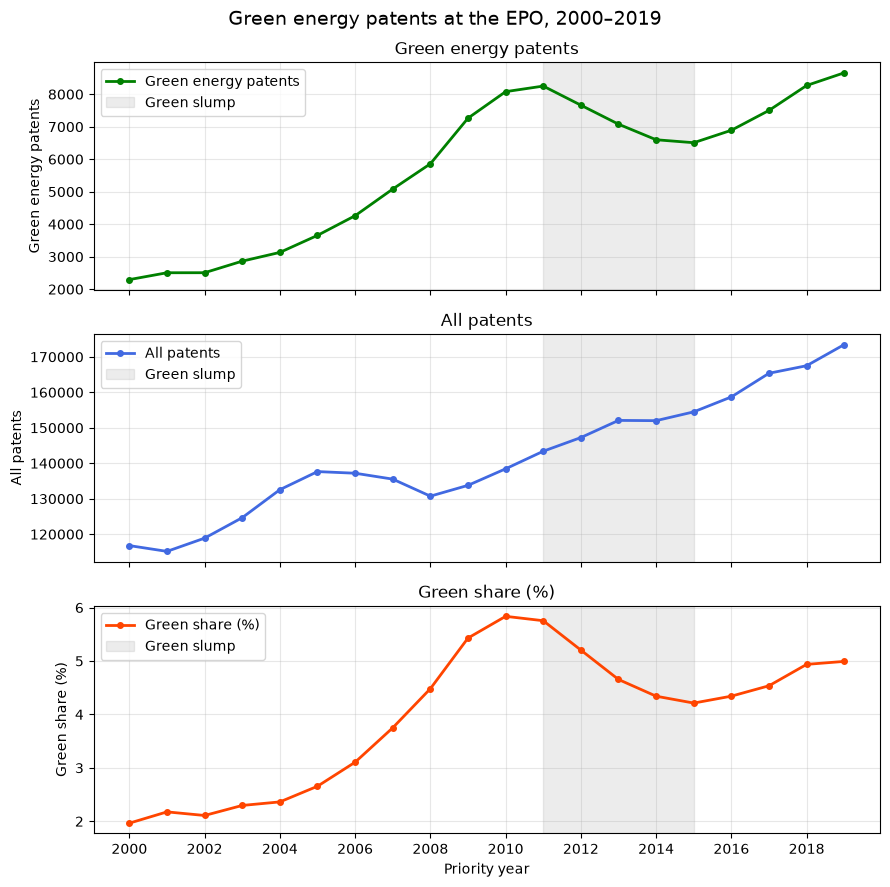

In [131]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
panel_colors = ['green', 'royalblue', 'orangered']

for ax, column, color in zip(axes, yearly.columns, panel_colors):
    ax.plot(
        yearly.index, yearly[column], color=color, lw=2, marker='o', ms=4, label=column
    )
    # Shade the slump (from the peak to the trough of green patenting) in every panel
    ax.axvspan(slump_start, slump_end, color='grey', alpha=0.15, label='Green slump')
    ax.set_ylabel(column)
    ax.set_title(column)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper left')

axes[-1].set_xlabel('Priority year')
axes[-1].set_xticks(yearly.index[::2])
fig.suptitle('Green energy patents at the EPO, 2000–2019', fontsize=14)
fig.tight_layout()
plt.show()

### Answers to Task 2

**Development 2000–2019.** Green energy patenting boomed in the 2000s. The number of green energy patents grew from
2,295 in 2000 to 8,251 in 2011, 3.6 times as many. The fastest growth was from 2006 to 2010. The green share of all
patents rose from 2.0% to a peak of 5.8% in 2010.

**The slump.** Yes, there is a clear slump. Green patenting peaked in **2011** and then fell four years in a row, to
6,508 in **2015** (−21.1%). It then recovered: from 2016 the number grew every year, and in 2019 it reached 8,660,
slightly above the 2011 peak. The green share fell from 5.8% (2011) to 4.2% (2015). It has since risen to 5.0%, but it
is still below the 2010 peak, because overall patenting grew in the meantime.

**Green-specific or general?** The slump is **specific to green energy**. During the green slump (2011–2015), the
number of all patents *grew* by 7.7%, from 143,392 to 154,489. Overall patenting dipped earlier, around the financial
crisis (2005–2008), when green patenting kept growing fast. The two series move differently in both periods, so the
green boom and slump are not a mirror of patenting in general. The green share falls during the slump because green
patents fall while all patents rise.

## Task 3 — How has the technology mix changed?

The periods are made with `pd.cut`, with bins `(1999, 2004]`, `(2004, 2009]`, and so on, so no period is hard-coded.
Since `green_cat` has one row per patent and main group, a patent in two main groups counts once in each. Therefore
the shares are shares of the *main-group counts* in a period, which add up to 100%.

In [ ]:
# Only the main-group rows (Table 1) of green_cat
main = green_cat.loc[green_cat['category'].isin(main_group_labels)]

# Five-year periods, labelled e.g. '2000–2004'
period_starts = range(sample_start, sample_end + 1, 5)
period = pd.cut(
    main['prio_year'],
    bins=[sample_start - 1, *[start + 4 for start in period_starts]],
    labels=[f'{start}–{start + 4}' for start in period_starts],
).rename('Period')

# Counts per period and main group, and each main group's share of the period
mix_counts = main.groupby([period, 'category']).size().unstack()
mix_counts = mix_counts[main_group_labels]
mix_shares = mix_counts.div(mix_counts.sum(axis=1), axis=0) * 100

mix_counts

category,Renewable energy,Efficient combustion,Nuclear energy,Efficient power transmission,Non-fossil fuels,Storage and hydrogen,Other energy conversion
Period,,,,,,,
2000–2004,3136,705,499,287,764,8243,106
2005–2009,10676,1279,738,475,2554,11180,356
2010–2014,15080,1691,1145,875,2910,17426,604
2015–2019,11797,934,1063,903,1792,22478,559


In [133]:
# Shares in percent; the last column shows that every period adds up to 100
mix_shares.assign(Total=mix_shares.sum(axis=1)).round(1)

category,Renewable energy,Efficient combustion,Nuclear energy,Efficient power transmission,Non-fossil fuels,Storage and hydrogen,Other energy conversion,Total
Period,,,,,,,,
2000–2004,22.8,5.1,3.6,2.1,5.6,60.0,0.8,100.0
2005–2009,39.2,4.7,2.7,1.7,9.4,41.0,1.3,100.0
2010–2014,38.0,4.3,2.9,2.2,7.3,43.9,1.5,100.0
2015–2019,29.8,2.4,2.7,2.3,4.5,56.9,1.4,100.0


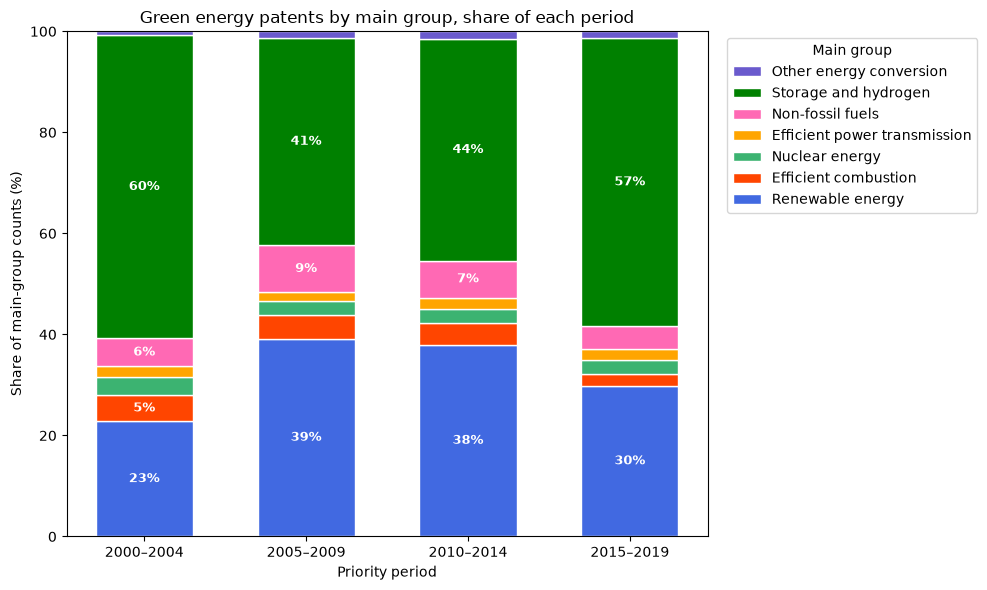

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

bottom = pd.Series(0.0, index=mix_shares.index)
for group in main_group_labels:
    bars = ax.bar(
        mix_shares.index,
        mix_shares[group],
        bottom=bottom,
        color=main_group_colors[group],
        edgecolor='white',
        linewidth=1,
        width=0.6,
        label=group,
    )
    # Write the share on segments that are large enough to hold a label
    ax.bar_label(
        bars,
        labels=[f'{v:.0f}%' if v >= 5 else '' for v in mix_shares[group]],
        label_type='center',
        color='white',
        fontsize=9,
        fontweight='bold',
    )
    bottom += mix_shares[group]

ax.set_title('Green energy patents by main group, share of each period')
ax.set_xlabel('Priority period')
ax.set_ylabel('Share of main-group counts (%)')
ax.set_ylim(0, 100)
# Legend outside the plot area so it does not cover the bars; reversed so it
# follows the stacking order from top to bottom
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1],
    labels[::-1],
    title='Main group',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
)
fig.tight_layout()
plt.show()

### Answers to Task 3

**Which main groups dominate?** Two main groups make up most of green energy patenting: **Storage and hydrogen** and
**Renewable energy**. Together they account for 80–87% of the main-group counts in every period. Non-fossil fuels
(mostly biofuels) is the third largest group, with 4.5–9.4%. The other four groups are small, with at most about 5% each.

**How has the mix changed?**

* **Renewable energy** drove the boom. Its share rose from 22.8% in 2000–2004 to 39.2% in 2005–2009 and stayed high in
  2010–2014 (38.0%). Its count grew almost fivefold, from 3,136 to 15,080. In 2015–2019 it fell to 11,797 patents
  (−22%) and a share of 29.8%.
* **Storage and hydrogen** had a falling share during the boom (60.0% → 41.0%), because the other groups grew faster.
  But its count grew in every period, from 8,243 to 22,478, and its share was back at 56.9% in 2015–2019.
* **Non-fossil fuels** followed the same boom-and-slump pattern as renewables. Its share peaked at 9.4% in 2005–2009,
  and its count fell from 2,910 to 1,792 between the last two periods. Efficient combustion shrank from 5.1% to 2.4%.

**Relation to the slump in Task 2.** The slump comes from the technologies that drove the boom. From 2010–2014 to
2015–2019, renewable energy lost 3,283 patents and non-fossil fuels lost 1,118. Storage and hydrogen kept growing and
added 5,052 patents in the same comparison, which is why total green patenting recovered after 2015. In short, the mix
shifted from energy *generation* (solar, wind, biofuels) towards *storage and hydrogen* (e.g. batteries and fuel
cells).

## Task 4 — Wind versus solar

The technology rows of `green_cat` already count every patent once per technology, so the yearly counts per technology
are a single `pd.crosstab` of priority year against category.

In [ ]:
tech = green_cat.loc[green_cat['category'].isin(technology_labels)]
tech_year = pd.crosstab(tech['prio_year'], tech['category'])
tech_year = tech_year[technology_labels]
tech_year.index.name = 'Priority year'
tech_year.head()

category,Solar,Wind,Other renewables
Priority year,,,
2000,306,116,34
2001,334,182,52
2002,328,151,54
2003,467,222,74
2004,548,244,109


In [136]:
# Peak table: everything is computed from tech_year, nothing is typed in by hand
peaks = pd.DataFrame(
    {
        'Peak year': tech_year.idxmax(),
        'Patents in peak year': tech_year.max(),
        f'Patents in {sample_end}': tech_year.loc[sample_end],
    }
)
peaks[f'Change peak→{sample_end} (%)'] = (
    (peaks[f'Patents in {sample_end}'] / peaks['Patents in peak year'] - 1) * 100
).round(1)
peaks = peaks.sort_values('Patents in peak year', ascending=False)
peaks.index.name = 'Technology'
peaks

,Peak year,Patents in peak year,Patents in 2019,Change peak→2019 (%)
Technology,,,,
Solar,2010,2323,1093,-52.9
Wind,2011,1188,1024,-13.8
Other renewables,2011,296,172,-41.9


To judge whether a technology *recovered*, we also find the lowest year after each peak and how much the count has
changed from that trough to 2019.

In [137]:
# For each technology: the lowest year after its peak (idxmin returns the year, not the position)
rows = []
for technology in peaks.index:
    peak_year = peaks.loc[technology, 'Peak year']
    after_peak = tech_year.loc[peak_year:, technology]
    rows.append(
        {
            'Technology': technology,
            'Trough year after peak': after_peak.idxmin(),
            'Patents in trough year': after_peak.min(),
        }
    )
recovery = pd.DataFrame(rows).set_index('Technology')
recovery[f'Change trough→{sample_end} (%)'] = (
    (peaks[f'Patents in {sample_end}'] / recovery['Patents in trough year'] - 1) * 100
).round(1)
recovery.index.name = 'Technology'
recovery

,Trough year after peak,Patents in trough year,Change trough→2019 (%)
Technology,,,
Solar,2019,1093,0.0
Wind,2015,782,30.9
Other renewables,2018,167,3.0


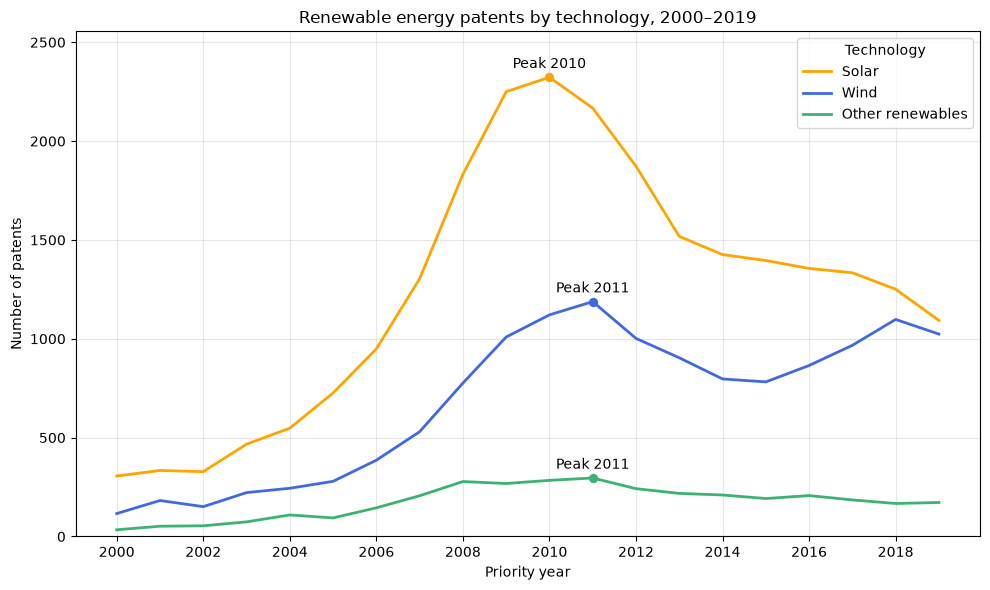

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

for technology in technology_labels:
    color = tech_colors[technology]
    ax.plot(tech_year.index, tech_year[technology], color=color, lw=2, label=technology)
    # Mark the peak with a point and label it with the peak year
    peak_year = peaks.loc[technology, 'Peak year']
    peak_count = peaks.loc[technology, 'Patents in peak year']
    ax.scatter(peak_year, peak_count, color=color, s=60, edgecolor='white')
    ax.text(peak_year, peak_count + 30, f'Peak {peak_year}', ha='center', va='bottom')

ax.set_title('Renewable energy patents by technology, 2000–2019')
ax.set_xlabel('Priority year')
ax.set_ylabel('Number of patents')
ax.set_xticks(tech_year.index[::2])
ax.set_ylim(0, peaks['Patents in peak year'].max() * 1.1)
ax.grid(alpha=0.3)
ax.legend(title='Technology')
fig.tight_layout()
plt.show()

### Answers to Task 4

**Which technologies collapsed after their peak?**

* **Solar** had by far the largest boom and the deepest collapse. It peaked in **2010** with 2,323 patents, fell
  quickly after 2011, and kept falling to 1,093 in 2019 (**−52.9%** from the peak). The lowest year after the peak is
  2019 itself, so solar had not recovered at all by the end of the sample.
* **Wind** peaked a year later, in **2011**, with 1,188 patents, and fell to 782 in 2015 (−34%).
* **Other renewables** is much smaller. It peaked in **2011** with 296 patents and drifted down to 172 in 2019
  (**−41.9%**).

**Did any of them recover?** Only **wind** recovered. From its trough in 2015 it grew by 30.9% to 1,024 patents in 2019,
which is only 13.8% below its peak. Other renewables has stayed flat near its low (+3.0% from its 2018 trough), and
solar is still falling. The solar collapse is the main reason why renewable energy patenting slumped in Tasks 2 and 3.
By 2019, wind (1,024) has almost caught up with solar (1,093), although solar had about twice as many patents at the
peak.

## Task 5 — Who drives green energy innovation?

We merge the applicants with `green_cat` once. Because `green_cat` has exactly one row per patent and category, each
applicant appears once per category of its patent, and summing `app_share` gives the fractional count without double
counting. The few green patents without applicant data drop out of the merge.

In [ ]:
green_app = applicants.merge(green_cat, on='appln_id')

# Sanity check: in each category, the fractional counts add up to the number of
# patents with applicant data (since the shares of a patent add up to 1)
check = green_app.groupby('category').agg(
    patents=('appln_id', 'nunique'),
    fractional=('app_share', 'sum'),
)
check.loc[all_labels].round(1)

,patents,fractional
category,,
Renewable energy,40678,40676.5
Efficient combustion,4609,4609.0
Nuclear energy,3445,3444.5
Efficient power transmission,2538,2538.0
Non-fossil fuels,8016,8016.0
Storage and hydrogen,59324,59323.5
Other energy conversion,1625,1625.0
Solar,24779,24777.5
Wind,13634,13634.0


In [ ]:
# The two ways of grouping that top_n supports, and the column each one uses
BY_COLUMNS = {'country': 'ctry_code', 'applicant': 'app_name'}


def top_n(data, category, by, start=sample_start, end=sample_end, n=10):
    """Return the n countries or applicants with the most patents in a category.

    Patents are counted fractionally: an applicant (or country) gets the sum of
    its ``app_share`` over the patents in the category and period.

    Parameters
    ----------
    data : pandas.DataFrame
        Applicants merged with ``green_cat`` (columns ``app_name``,
        ``ctry_code``, ``app_share``, ``category`` and ``prio_year``).
    category : str
        A label from Table 1 (e.g. ``'Storage and hydrogen'``) or Table 2
        (e.g. ``'Wind'``).
    by : {'country', 'applicant'}
        Whether to rank countries or applicants.
    start, end : int, optional
        First and last priority year of the period (inclusive).
    n : int, optional
        Number of countries or applicants to return.

    Returns
    -------
    pandas.DataFrame
        The top n, largest first, with the column ``patents``. For applicants,
        the column ``country`` gives the applicant's most common country in the
        selection.

    Raises
    ------
    ValueError
        If ``category`` or ``by`` is not valid, or if ``start > end``.
    """
    if category not in all_labels:
        raise ValueError(f'Unknown category {category!r}. Choose one of {all_labels}')
    if by not in BY_COLUMNS:
        raise ValueError(f'Unknown by={by!r}. Choose one of {list(BY_COLUMNS)}')
    if start > end:
        raise ValueError(f'start ({start}) must not be after end ({end})')

    selected = data.loc[
        (data['category'] == category) & data['prio_year'].between(start, end)
    ]
    top = (
        selected.groupby(BY_COLUMNS[by])['app_share']
        .sum()
        .nlargest(n)
        .to_frame('patents')
    )
    if by == 'applicant':
        # Most common country of each top applicant (only n small groups)
        top_rows = selected.loc[selected['app_name'].isin(top.index)]
        top['country'] = top_rows.groupby('app_name')['ctry_code'].agg(
            lambda countries: countries.value_counts().idxmax()
        )
    top.index.name = by.capitalize()
    return top

A quick test shows that the function works for another category and that it gives a clear error for a wrong input:

In [141]:
display(top_n(green_app, 'Storage and hydrogen', 'country', 2015, 2019, n=5).round(1))

try:
    top_n(green_app, 'Hydro power', 'country')
except ValueError as error:
    print('ValueError:', error)

,patents
Country,
JP,5677.5
KR,4209.8
US,2998.0
DE,2624.3
CN,2030.8


ValueError: Unknown category 'Hydro power'. Choose one of ['Renewable energy', 'Efficient combustion', 'Nuclear energy', 'Efficient power transmission', 'Non-fossil fuels', 'Storage and hydrogen', 'Other energy conversion', 'Solar', 'Wind', 'Other renewables']


In [142]:
def plot_top_bars(ax, top, title, color, xlabel='Patents (fractional count)'):
    """Draw a horizontal bar chart of a top-n table, with the largest at the top.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axes to draw on.
    top : pandas.DataFrame
        Output of :func:`top_n`. If it has a ``country`` column, the country
        is added to each label.
    title : str
        Panel title.
    color : str
        Bar colour.
    xlabel : str, optional
        Label of the x-axis.
    """
    # Shorten very long applicant names so the bars keep enough room
    labels = top.index.where(top.index.str.len() <= 40, top.index.str[:38] + '…')
    if 'country' in top:
        labels = labels + ' (' + top['country'].astype(str) + ')'
    bars = ax.barh(labels, top['patents'], color=color, label=xlabel)
    ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=9)
    ax.invert_yaxis()  # largest at the top
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis='x', alpha=0.3)
    ax.legend(loc='lower right')

### Countries in renewable energy

We call `top_n` once per period and keep the results, so the table and the figure use the same numbers.

In [143]:
country_periods = [(2005, 2009), (2015, 2019)]
top_countries = {
    f'{start}–{end}': top_n(green_app, 'Renewable energy', 'country', start, end)
    for start, end in country_periods
}

# The two top-10 lists side by side
pd.concat(
    [top.reset_index() for top in top_countries.values()],
    axis=1,
    keys=top_countries.keys(),
).round(1)

2005–2009         2015–2019        
    Country patents   Country patents
0        US  2628.1        DE  2133.7
1        DE  2216.3        US  1750.3
2        JP  1530.5        DK  1501.3
3        DK   493.5        JP  1114.1
4        KR   450.7        KR   886.0
5        FR   424.7        CN   836.0
6        ES   342.1        FR   643.9
7        GB   331.3        ES   383.0
8        IT   280.5        GB   359.0
9        CH   257.8        NL   310.8

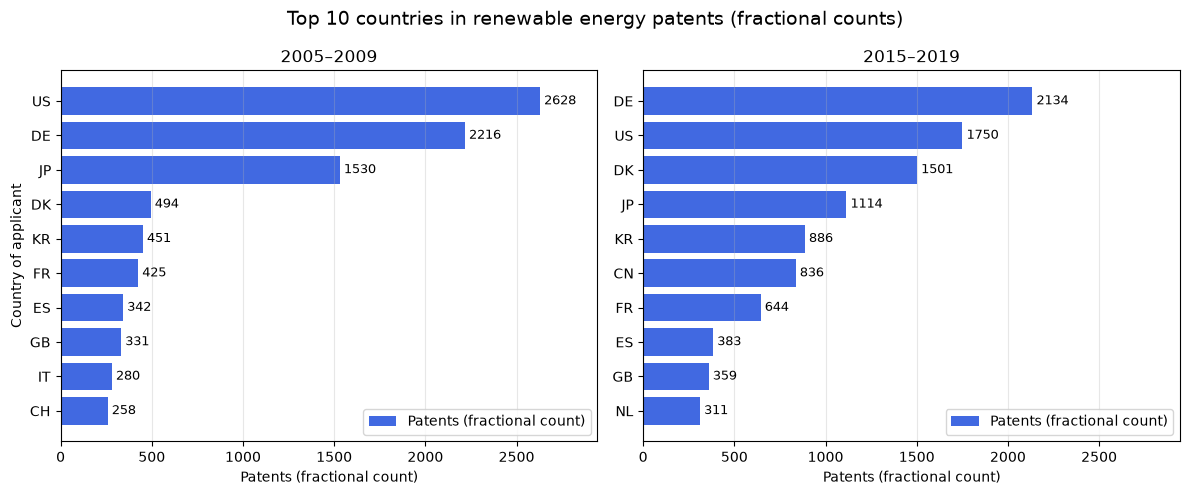

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for ax, (period_label, top) in zip(axes, top_countries.items()):
    plot_top_bars(ax, top, period_label, main_group_colors['Renewable energy'])
axes[0].set_ylabel('Country of applicant')
# sharex=True gives both panels the same scale; add room for the bar labels
axes[0].set_xlim(0, max(top['patents'].max() for top in top_countries.values()) * 1.12)

fig.suptitle(
    'Top 10 countries in renewable energy patents (fractional counts)', fontsize=14
)
fig.tight_layout()
plt.show()

### Applicants in solar and wind

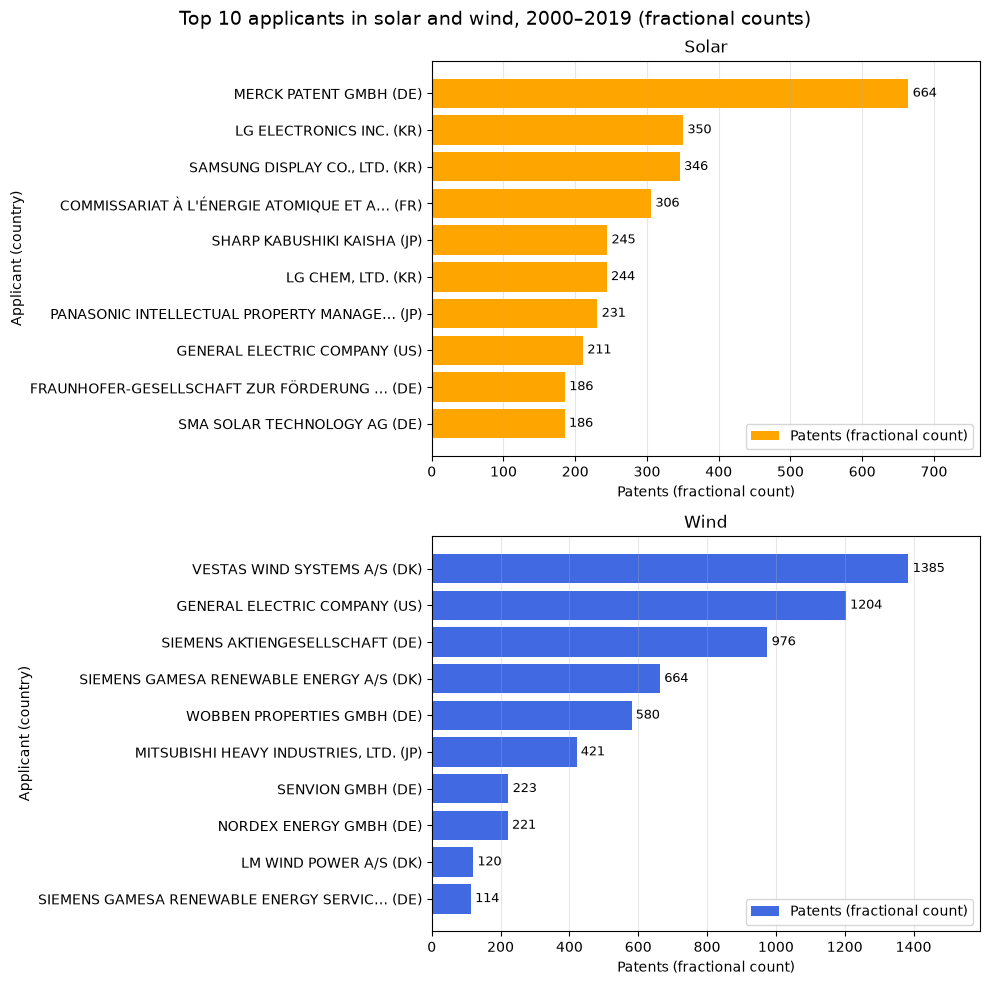

In [ ]:
top_applicants = {
    technology: top_n(green_app, technology, 'applicant')
    for technology in ['Solar', 'Wind']
}

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

for ax, (technology, top) in zip(axes, top_applicants.items()):
    plot_top_bars(ax, top, technology, tech_colors[technology])
    ax.set_xlim(0, top['patents'].max() * 1.15)
    ax.set_ylabel('Applicant (country)')

fig.suptitle(
    f'Top 10 applicants in solar and wind, {sample_start}–{sample_end} (fractional counts)',
    fontsize=14,
)
fig.tight_layout()
plt.show()

To see whether the applicants explain the changes among countries, we also look at the top applicants in renewable
energy in the same two periods as the country figure.

In [146]:
pd.concat(
    [
        top_n(green_app, 'Renewable energy', 'applicant', start, end).reset_index()
        for start, end in country_periods
    ],
    axis=1,
    keys=top_countries.keys(),
).round(1)

2005–2009                  \
                                           Applicant patents country   
0                           GENERAL ELECTRIC COMPANY   492.0      US   
1                            VESTAS WIND SYSTEMS A/S   317.0      DK   
2                         SIEMENS AKTIENGESELLSCHAFT   203.5      DE   
3                             SHARP KABUSHIKI KAISHA   149.7      JP   
4                  MITSUBISHI HEAVY INDUSTRIES, LTD.   142.5      JP   
5                                  MERCK PATENT GMBH   130.0      DE   
6               E. I. DU PONT DE NEMOURS AND COMPANY    87.5      US   
7                           SANYO ELECTRIC CO., LTD.    86.0      JP   
8  FRAUNHOFER-GESELLSCHAFT ZUR FÖRDERUNG DER ANGE...    85.2      DE   
9                                LG ELECTRONICS INC.    83.0      KR   

                                           2015–2019                  
                                           Applicant patents country  
0                            VESTAS WIND SYSTEMS A/S   588.8      DK  
1                SIEMENS GAMESA RENEWABLE ENERGY A/S   583.5      DK  
2                           GENERAL ELECTRIC COMPANY   341.0      US  
3                             WOBBEN PROPERTIES GMBH   333.0      DE  
4                          SAMSUNG DISPLAY CO., LTD.   277.3      KR  
5                                  MERCK PATENT GMBH   170.0      DE  
6                         SIEMENS AKTIENGESELLSCHAFT   132.5      DE  
7                                LG ELECTRONICS INC.   123.0      KR  
8  COMMISSARIAT À L'ÉNERGIE ATOMIQUE ET AUX ÉNERG...    97.1      FR  
9           GENERAL ELECTRIC RENOVABLES ESPAÑA, S.L.    95.0      ES

### Answers to Task 5

**Which countries lead, and how has this changed?** In 2005–2009, the **US** led renewable energy patenting (2,628
patents), ahead of **Germany** (2,216) and **Japan** (1,530). No other country had more than 500. In 2015–2019,
**Germany** led (2,134, almost unchanged at −4%), while the US fell by 33% to 1,750 and Japan by 27% to 1,114.
**Denmark** tripled its count, from 494 to 1,501, and moved from 4th to 3rd place. **South Korea** almost doubled
(451 → 886), and **China** entered the top 10 in 6th place (836). Italy and Switzerland dropped out of the top 10, and
the Netherlands came in.

**Which organisations dominate solar and wind?**

* **Solar** is dominated by large **electronics and chemicals conglomerates** from East Asia and Germany: Merck Patent
  (DE, by far the largest with 664 patents, materials for solar cells), LG Electronics, Samsung Display and LG Chem
  (KR), Sharp and Panasonic (JP), and General Electric (US). Two **public research institutes** are also in the top 10:
  CEA (FR) and Fraunhofer (DE). SMA Solar Technology (DE, inverters) is the only solar specialist. Solar is
  fragmented: the top 10 hold only about 12% of all solar patents.
* **Wind** is dominated by **specialised wind-turbine makers**, mostly from Denmark and Germany: Vestas (DK, 1,385),
  Siemens Gamesa (DK and DE), Wobben Properties (DE, which holds the patents of the turbine maker Enercon), Senvion,
  Nordex (DE) and the blade maker LM Wind Power (DK). The rest of the top 10 are **industrial conglomerates** with a
  wind business: General Electric (US), Siemens (DE) and Mitsubishi Heavy Industries (JP). No research institutes are
  in the top 10. Wind is concentrated: the top 10 hold about 43% of all wind patents.

**Do the applicants explain the changes among countries?** Largely yes, as the table of top renewable energy applicants
by period shows.

* **Denmark's rise** comes from the wind specialists. Vestas grew from 317 to 589 patents, and Siemens Gamesa Renewable
  Energy A/S, Siemens' Danish wind business, became the second largest applicant (584). At the same time, Siemens AG in
  Germany fell from 204 to 133, so part of Siemens' wind patenting moved from a German to a Danish applicant.
* **The US decline** follows General Electric, the largest applicant in 2005–2009 (492), which fell to 341. Part of
  GE's wind patents are now filed by its Spanish subsidiary (GE Renovables España, 95), which counts for Spain.
* **Japan's decline** follows the solar collapse. Sharp, Sanyo and Mitsubishi Heavy Industries are in the top 10 in
  2005–2009 but not in 2015–2019. **Korea's rise** follows Samsung Display and LG Electronics.
* **Germany held its position** because wind (Wobben/Enercon, Siemens) and solar materials (Merck) partly offset each
  other.

Because solar collapsed while wind recovered (Task 4), the countries with wind champions (Denmark, Germany) gained
relative to those whose renewable patenting relied on solar electronics (Japan, the US).

## Task 6 — Use of online resources

> **DRAFT — the group must check and edit this statement before submission.**

We used the generative AI tool **Claude Code** (Anthropic), run inside VS Code, while solving the term paper:

* **Planning:** to plan the data pipeline, i.e. which columns and rows to read from each file, the reader functions, and
  the tidy tables (`sample`, `green_cat`, `applicants`) that Tasks 2–5 reuse.
* **Code:** to write and debug the code. Examples are finding the de-duplication rule for applicants that matches the
  `app_share` checkpoint, and fixing how the start and end years of the slump are found from the data.
* **Text:** to draft the markdown explanations and answers.

We checked all the code by running the notebook, compared the numbers with the checkpoints in the task, and read the
answers against the tables and figures. We edited the text where needed. The final assessments are our own.

We also used the official **pandas** documentation (`read_csv`, `pd.cut`, `groupby`) and the
**matplotlib** documentation (`bar_label`, `annotate`). No code was copied directly from other online sources.